In [1]:
import xarray as xr
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

In [2]:
def get_run_names(str_list):
    run_names = []
    for i,string in enumerate(str_list):
        run_names.append(string.split("_")[0]+'_'+string.split("_")[1])
    return run_names

In [3]:
def normalize(DA):
    start_date = '2020-06-30T12:00:00.000000000'
    end_date = '2100-06-30T12:00:00.000000000'
    mean = DA.loc[start_date:end_date].mean('time')
    std_dev = DA.loc[start_date:end_date].std('time')
    normalized_DA = (DA-mean)/std_dev
    return normalized_DA

In [4]:
def rollmean(DA,n_months=3*10):
    running_mean = DA.rolling(time=n_months,center='True').mean('time')#.fillna(0)
    return running_mean

In [5]:
'''
Importing the datasets GHA
'''
import os
# Path to the dataset directory
GHA_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_all = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'all' in f# and 'CanESM' in f 
]

GHA_file_list_all = sorted(GHA_file_list_all)

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_retrograding = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'retrograding' in f# and 'CanESM' in f 
]

GHA_file_list_retrograding = sorted(GHA_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
GHA_file_list_upstream = [
    f for f in os.listdir(GHA_path) 
    if os.path.isfile(os.path.join(GHA_path, f)) and 'GHA' in f and 'upstream' in f# and 'CanESM' in f 
]

GHA_file_list_upstream = sorted(GHA_file_list_upstream)

#import data
GHA_DAs_all = []
for name in GHA_file_list_all:
    GHA_DAs_all.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))
#import data
GHA_DAs_retrograding = []
for name in GHA_file_list_retrograding:
    GHA_DAs_retrograding.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))
#import data
GHA_DAs_upstream = []
for name in GHA_file_list_upstream:
    GHA_DAs_upstream.append(normalize(xr.open_dataset(name)['GHA monthly blocking frequency']))

#compute ensemble average
GHA_combined_all = xr.concat(GHA_DAs_all, dim='ensemble')
GHA_average_all = GHA_combined_all.mean(dim='ensemble')
GHA_combined_retrograding = xr.concat(GHA_DAs_retrograding, dim='ensemble')
GHA_average_retrograding = GHA_combined_retrograding.mean(dim='ensemble')
GHA_combined_upstream = xr.concat(GHA_DAs_upstream, dim='ensemble')
GHA_average_upstream = GHA_combined_upstream.mean(dim='ensemble')

#import ERA5 GHA frequency
GHA_ERA5_all = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_all_GHA_historical.nc')['GHA monthly blocking frequency'])
GHA_ERA5_retrograding = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_retrograding_GHA_historical.nc')['GHA monthly blocking frequency'])
GHA_ERA5_upstream = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_upstream_GHA_historical.nc')['GHA monthly blocking frequency'])

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370


In [6]:
'''
Importing the datasets DAV
'''
import os
# Path to the dataset directory
DAV_path = "/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/"

%cd /emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370/

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_all = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'all' in f# and 'CanESM' in f 
]

DAV_file_list_all = sorted(DAV_file_list_all)

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_retrograding = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'retrograding' in f# and 'CanESM' in f 
]

DAV_file_list_retrograding = sorted(DAV_file_list_retrograding)

# List all files, excluding those with 'unfilt' in the name
DAV_file_list_upstream = [
    f for f in os.listdir(DAV_path) 
    if os.path.isfile(os.path.join(DAV_path, f)) and 'DAV' in f and 'upstream' in f# and 'CanESM' in f 
]

DAV_file_list_upstream = sorted(DAV_file_list_upstream)

#import data
DAV_DAs_all = []
for name in DAV_file_list_all:
    DAV_DAs_all.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))
#import data
DAV_DAs_retrograding = []
for name in DAV_file_list_retrograding:
    DAV_DAs_retrograding.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))
#import data
DAV_DAs_upstream = []
for name in DAV_file_list_upstream:
    DAV_DAs_upstream.append(normalize(xr.open_dataset(name)['DAV monthly blocking frequency']))

#compute ensemble average
DAV_combined_all = xr.concat(DAV_DAs_all, dim='ensemble')
DAV_average_all = DAV_combined_all.mean(dim='ensemble')
DAV_combined_retrograding = xr.concat(DAV_DAs_retrograding, dim='ensemble')
DAV_average_retrograding = DAV_combined_retrograding.mean(dim='ensemble')
DAV_combined_upstream = xr.concat(DAV_DAs_upstream, dim='ensemble')
DAV_average_upstream = DAV_combined_upstream.mean(dim='ensemble')

#import ERA5 DAV frequency
DAV_ERA5_all = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_all_DAV_historical.nc')['DAV monthly blocking frequency'])
DAV_ERA5_retrograding = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_retrograding_DAV_historical.nc')['DAV monthly blocking frequency'])
DAV_ERA5_upstream = normalize(xr.open_dataset('/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ERA5/ERA5_freq_upstream_DAV_historical.nc')['DAV monthly blocking frequency'])

/emmy-noether/home/mf671/github/greenland_blocking/frequency_data_arrays_2/ssp370


In [7]:
#compute linear regrassion GHA
from scipy.stats import linregress
x=np.arange(0,len(GHA_average_all),1)

#all
result = linregress(x,GHA_average_all)
GHA_y_all = result.intercept + result.slope*x
GHA_slope_all = result.slope * 3*10 #convert to %/per_decade
GHA_slope_stderr_all = result.stderr * 3*10

#retrograding
result = linregress(x,GHA_average_retrograding)
GHA_y_retrograding = result.intercept + result.slope*x
GHA_slope_retrograding = result.slope * 3*10
GHA_slope_stderr_retrograding = result.stderr * 3*10

#upstream
result = linregress(x,GHA_average_upstream)
GHA_y_upstream = result.intercept + result.slope*x
GHA_slope_upstream = result.slope * 3*10
GHA_slope_stderr_upstream = result.stderr * 3*10

In [8]:
#compute linear regrassion DAV
from scipy.stats import linregress
x=np.arange(0,len(DAV_average_all),1)

#all
result = linregress(x,DAV_average_all)
DAV_y_all = result.intercept + result.slope*x
DAV_slope_all = result.slope * 3*10 #convert to %/per_decade
DAV_slope_stderr_all = result.stderr * 3*10

#retrograding
result = linregress(x,DAV_average_retrograding)
DAV_y_retrograding = result.intercept + result.slope*x
DAV_slope_retrograding = result.slope * 3*10
DAV_slope_stderr_retrograding = result.stderr * 3*10

#upstream
result = linregress(x,DAV_average_upstream)
DAV_y_upstream = result.intercept + result.slope*x
DAV_slope_upstream = result.slope * 3*10
DAV_slope_stderr_upstream = result.stderr * 3*10

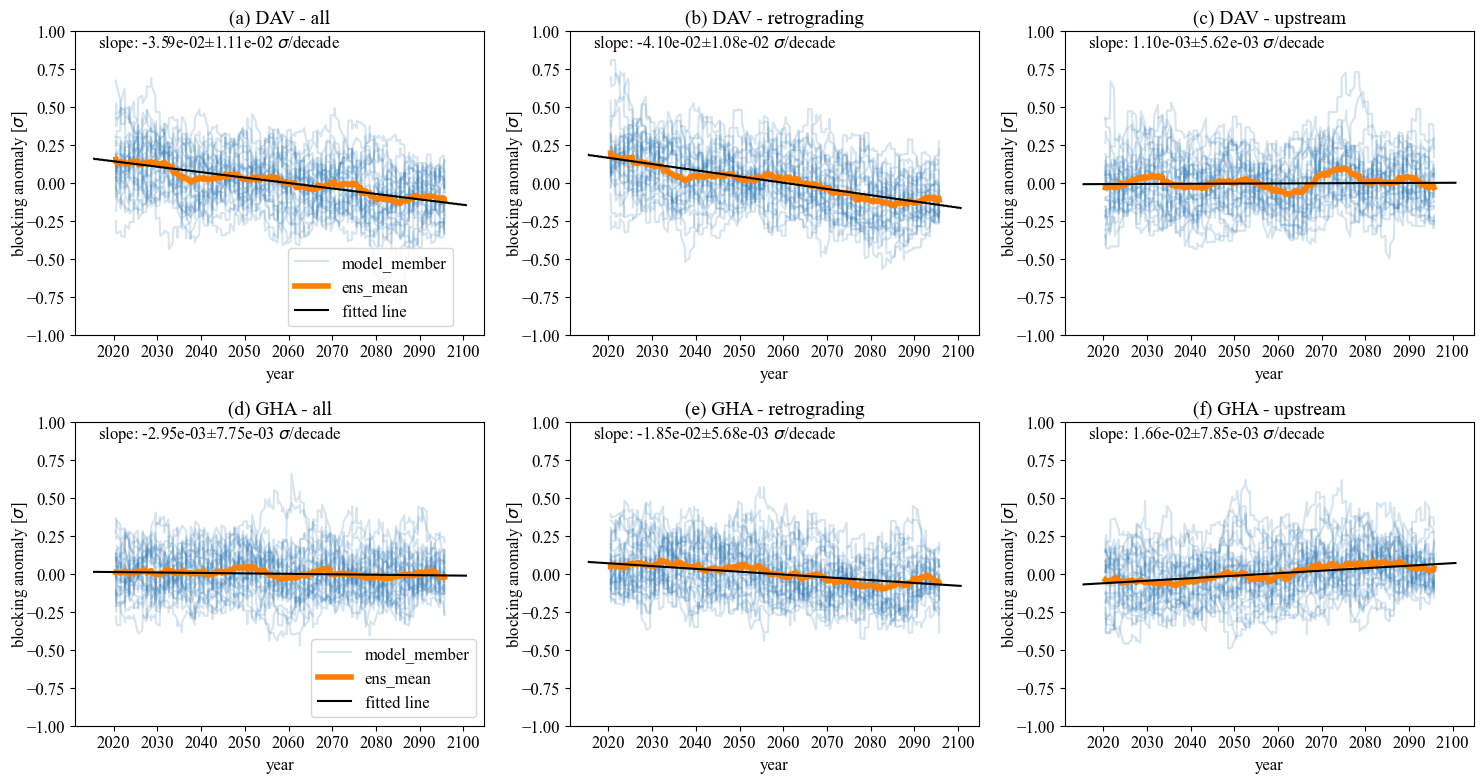

In [10]:
labels = ['all','retrograding (WBI > 0)','upstream (WBI < 0)']
widths = [2,0.6,0.6]

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8))
axes = axes.flatten()
#plt.suptitle('Monthly summer blocking frequency (JJA) given as fraction of blocked days')
colors = ['#377eb8', '#ff7f00', 'black']

axes[0].set_title('(a) DAV - all')
for i,element in enumerate(DAV_DAs_all):
    if i == 0:
        axes[0].plot(element['time'],rollmean(element),colors[0],alpha=0.2,label='model_member')
    else:
        axes[0].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[0].plot(DAV_average_all['time'],rollmean(DAV_average_all),colors[1],label='ens_mean',linewidth=4.0)
axes[0].plot(DAV_average_all['time'],DAV_y_all, colors[2], label='fitted line')
axes[0].text(DAV_average_all['time'][3], 0.9, 'slope: ' + f"{DAV_slope_all:.2e}" + "±" + f"{DAV_slope_stderr_all:.2e}" + r" $\sigma$/decade")
axes[0].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[0].set_xlabel('year')
axes[0].legend(loc='best', bbox_to_anchor=(0.5, 0., 0.5, 0.5))
axes[0].set_ylim(-1,1)

axes[1].set_title('(b) DAV - retrograding')
for element in DAV_DAs_retrograding:
    axes[1].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[1].plot(DAV_average_retrograding['time'],rollmean(DAV_average_retrograding),colors[1],linewidth=4.0)
axes[1].plot(DAV_average_retrograding['time'],DAV_y_retrograding,colors[2], label='fitted line')
axes[1].text(DAV_average_retrograding['time'][3], 0.9, 'slope: ' + f"{DAV_slope_retrograding:.2e}" + "±" + f"{DAV_slope_stderr_retrograding:.2e}"+ r" $\sigma$/decade")
axes[1].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[1].set_xlabel('year')
axes[1].set_ylim(-1,1)

axes[2].set_title('(c) DAV - upstream')
for element in DAV_DAs_upstream:
    axes[2].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[2].plot(DAV_average_upstream['time'],rollmean(DAV_average_upstream),colors[1],linewidth=4.0)
axes[2].plot(DAV_average_upstream['time'],DAV_y_upstream,colors[2], label='fitted line')
axes[2].text(DAV_average_upstream['time'][3], 0.9, 'slope: ' + f"{DAV_slope_upstream:.2e}" + "±" + f"{DAV_slope_stderr_upstream:.2e}"+ r" $\sigma$/decade")
axes[2].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[2].set_xlabel('year')
axes[2].set_ylim(-1,1)

axes[3].set_title('(d) GHA - all')
for i,element in enumerate(GHA_DAs_all):
    if i == 0:
        axes[3].plot(element['time'],rollmean(element),colors[0],alpha=0.2,label='model_member')
    else:
        axes[3].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[3].plot(GHA_average_all['time'],rollmean(GHA_average_all),colors[1],label='ens_mean',linewidth=4.0)
axes[3].plot(GHA_average_all['time'],GHA_y_all, colors[2], label='fitted line')
axes[3].text(GHA_average_all['time'][3], 0.9, 'slope: ' + f"{GHA_slope_all:.2e}" + "±" + f"{GHA_slope_stderr_all:.2e}" + r" $\sigma$/decade")
axes[3].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[3].set_xlabel('year')
axes[3].legend(loc='best', bbox_to_anchor=(0.5, 0., 0.5, 0.5))
axes[3].set_ylim(-1,1)

axes[4].set_title('(e) GHA - retrograding')
for element in GHA_DAs_retrograding:
    axes[4].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[4].plot(GHA_average_retrograding['time'],rollmean(GHA_average_retrograding),colors[1],linewidth=4.0)
axes[4].plot(GHA_average_retrograding['time'],GHA_y_retrograding,colors[2], label='fitted line')
axes[4].text(GHA_average_retrograding['time'][3], 0.9, 'slope: ' + f"{GHA_slope_retrograding:.2e}" + "±" + f"{GHA_slope_stderr_retrograding:.2e}"+ r" $\sigma$/decade")
axes[4].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[4].set_xlabel('year')
axes[4].set_ylim(-1,1)

axes[5].set_title('(f) GHA - upstream')
for element in GHA_DAs_upstream:
    axes[5].plot(element['time'],rollmean(element),colors[0],alpha=0.2)
axes[5].plot(GHA_average_upstream['time'],rollmean(GHA_average_upstream),colors[1],linewidth=4.0)
axes[5].plot(GHA_average_upstream['time'],GHA_y_upstream,colors[2], label='fitted line')
axes[5].text(GHA_average_upstream['time'][3], 0.9, 'slope: ' + f"{GHA_slope_upstream:.2e}" + "±" + f"{GHA_slope_stderr_upstream:.2e}"+ r" $\sigma$/decade")
axes[5].set_ylabel(r'blocking anomaly [$\sigma$]',labelpad=-2)
axes[5].set_xlabel('year')
axes[5].set_ylim(-1,1)

plt.tight_layout()

plt.savefig('/emmy-noether/home/mf671/github/greenland_blocking/CMIP6_future_analysis/PLOTS/TOT_future_frequency_trend_analysis.png',dpi=300)
